# 17 · Cohort Seasoning & Survivorship (`17_survivorship.py`)

Recent mortgage vintages (2023–2025) have not yet lived long enough to accumulate 12 or 24 months of default seasoning, while earlier cohorts show left-truncation if loans were acquired after origination. Here we verify `m2.survivorship_mart` read-only and plot vintage seasoning depth alongside late-entry shares (`late_share`) across acquisition quarters.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Cohort Seasoning &amp; Truncation Audit</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Loan Lifetime History</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">Origination vs acquisition date</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Seasoning Tiers</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">0-3m, 4-12m, >12m splits</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Truncation Share</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">late_share by vintage</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Survivorship Mart</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.survivorship_mart</text>
</svg></div>

We attach `module2_sample.duckdb` read-only, check key uniqueness on `m2.survivorship_mart`, and summarize seasoning milestones across selected vintage years.

In [1]:
# Load path, DuckDB, pandas, I/O, and inline chart display utilities
# Import standard libraries to inspect saved marts read-only and render 300 dpi figures inline
import io
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Verify composite unique key on survivorship_mart and inspect vintage seasoning depth
# Assert unique key integrity on (acquisition_quarter, cohort_metric) and summarize by year
n_tot, n_dist = con.execute("SELECT count(*), count(DISTINCT (acquisition_quarter, cohort_metric)) FROM m2.survivorship_mart").fetchone()
assert n_tot == n_dist, "Duplicate keys in survivorship_mart"
print(f"PASS  unique key on m2.survivorship_mart: {n_tot:,} rows")

con.execute("""
    SELECT left(acquisition_quarter, 4)::INTEGER AS acq_year,
           sum(loans)::BIGINT AS loans,
           round(100.0 * sum(seasoned_gt12m_loans) / NULLIF(sum(loans), 0), 1) AS pct_gt12m,
           round(100.0 * sum(seasoned_gt24m_loans) / NULLIF(sum(loans), 0), 1) AS pct_gt24m,
           round(avg(median_seasoning_months), 1) AS avg_median_mob,
           round(100.0 * avg(late_share), 1) AS avg_late_share_pct
    FROM m2.survivorship_mart
    WHERE cohort_metric = 'acquisition_seasoning'
      AND left(acquisition_quarter, 4)::INTEGER IN (2003, 2007, 2012, 2018, 2021, 2023, 2024, 2025)
    GROUP BY 1
    ORDER BY 1
""").fetchdf()

PASS  unique key on m2.survivorship_mart: 297 rows


,acq_year,loans,pct_gt12m,pct_gt24m,avg_median_mob,avg_late_share_pct
0,2003,1698,0.0,0.0,0.5,1.7
1,2007,373,0.3,0.0,0.5,2.3
2,2012,785,0.0,0.0,0.0,1.1
3,2018,550,0.0,0.0,0.0,1.2
4,2021,1435,0.0,0.0,0.0,1.5
5,2023,291,0.3,0.0,0.0,0.7
6,2024,291,0.0,0.0,0.3,0.8
7,2025,290,0.3,0.0,0.0,0.7


Next we plot the share of each acquisition vintage surviving past 24 months (`seasoned_gt24m_loans / loans`) against >12-month seasoned share so right-censoring in 2024–2025 cohorts is immediately visible.

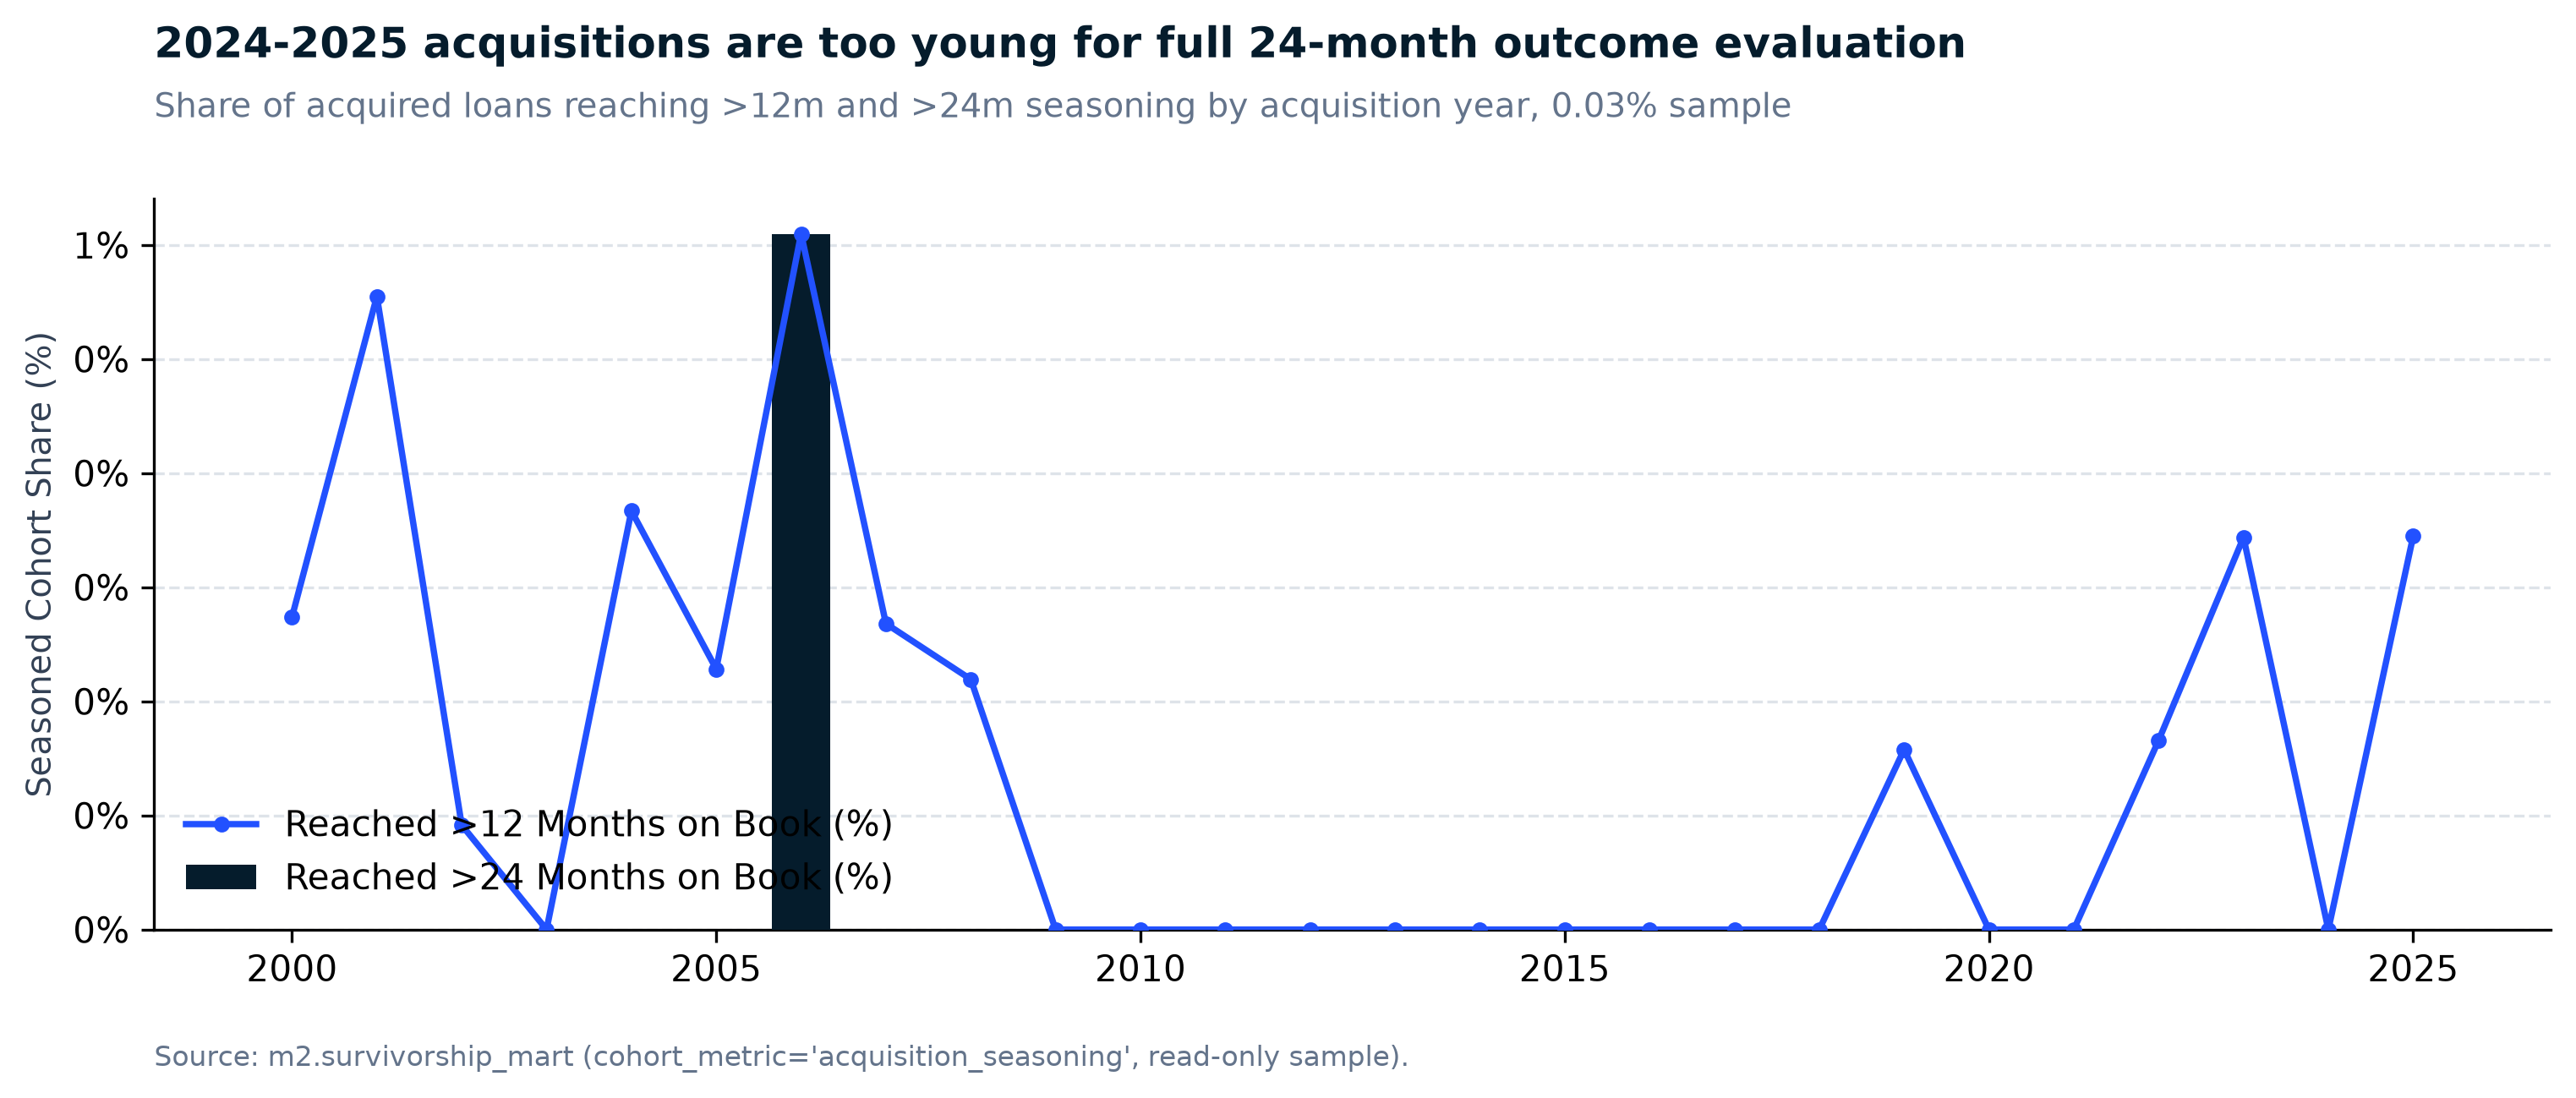

In [2]:
# Plot >24m seasoned loan share by acquisition cohort year (showing 2024-2025 right-censoring)
# Query acquisition_seasoning metrics aggregated by year and draw 300 dpi bars via BytesIO
surv_yr = con.execute("""
    SELECT left(acquisition_quarter, 4)::INTEGER AS acq_year,
           100.0 * sum(seasoned_gt24m_loans) / NULLIF(sum(loans), 0) AS pct_gt24m,
           100.0 * sum(seasoned_gt12m_loans) / NULLIF(sum(loans), 0) AS pct_gt12m
    FROM m2.survivorship_mart
    WHERE cohort_metric = 'acquisition_seasoning'
    GROUP BY 1
    ORDER BY 1
""").fetchdf()

fig, ax = plt.subplots(figsize=(10.5, 4.3), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.bar(surv_yr["acq_year"], surv_yr["pct_gt24m"], width=0.68, color="#051C2C", label="Reached >24 Months on Book (%)", zorder=3)
ax.plot(surv_yr["acq_year"], surv_yr["pct_gt12m"], color="#2251FF", marker="o", markersize=3.5, linewidth=1.8, label="Reached >12 Months on Book (%)", zorder=4)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Seasoned Cohort Share (%)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="lower left")
fig.text(0.07, 0.94, "2024-2025 acquisitions are too young for full 24-month outcome evaluation", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Share of acquired loans reaching >12m and >24m seasoning by acquisition year, 0.03% sample", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.survivorship_mart (cohort_metric='acquisition_seasoning', read-only sample).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()